# 05 — Delay minutes: a good metric, and can a model catch them?

**Goal.** The main model ranks incidents by their risk of becoming *major* (a safety
response or a delay of 30+ min). In its top 10% it catches about 39% of major incidents
but only about 15% of delay minutes. Two questions follow:

1. **Is delay minutes a good metric** for this data, or should the headline stay on
   safety and major incidents?
2. **Can a model aimed at minutes catch more of them?**

Everything here uses the cleaned data, the labels and the rolling backtest folds of
`code/modeling/` (train on the past, test on 2021, 2022 and 2023). The 2024-25 holdout
is not used.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import d2_tweedie_score

# The notebook lives in code/exploration/; the project modules live in code/.
sys.path.insert(0, str(Path.cwd().parent))
import config
from cleaning.load import load_incidents
from modeling.backtest import FOLDS, capture, run_backtest
from modeling.costs import delay_minutes
from modeling.features import MAIN_FEATURES, build_features
from modeling.target import add_targets, model_population

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Load train incidents and their delay minutes

Delay minutes are counted at the **lower bound** of each delay bucket
(`costs.delay_minutes`): a 10-14 min incident counts as 10, a 30+ min incident as 30.
Section 2 looks at what that choice does. `before_holdout` keeps 2019-2023 only.

In [2]:
labelled = add_targets(model_population(load_incidents()))
minutes = delay_minutes(labelled)
year = labelled["service_date"].dt.year
before_holdout = year <= 2023

print(f"Train incidents 2019-2023: {before_holdout.sum():,}   "
      f"delay minutes (lower bound): {minutes[before_holdout].sum():,.0f}")

Train incidents 2019-2023: 21,058   delay minutes (lower bound): 54,446


## 2. Is delay minutes a good metric?

### 2a. Where the minutes come from

Share of incidents and share of delay minutes in each delay bucket.

In [3]:
pre = labelled[before_holdout]
by_bucket = pd.DataFrame({
    "incidents": pre.groupby("delay_bucket", observed=True).size(),
    "minutes": minutes[before_holdout].groupby(pre["delay_bucket"], observed=True).sum(),
})
by_bucket["% of incidents"] = 100 * by_bucket["incidents"] / by_bucket["incidents"].sum()
by_bucket["% of minutes"] = 100 * by_bucket["minutes"] / by_bucket["minutes"].sum()
by_bucket.round(1)

,incidents,minutes,% of incidents,% of minutes
delay_bucket,,,,
02 min et moins,11845,0.0,56.2,0.0
03 à 04 min,4657,13971.0,22.1,25.7
05 à 09 min,3145,15725.0,14.9,28.9
10 à 14 min,651,6510.0,3.1,12.0
15 à 19 min,206,3090.0,1.0,5.7
20 à 24 min,108,2160.0,0.5,4.0
25 à 29 min,78,1950.0,0.4,3.6
30 min et plus,368,11040.0,1.7,20.3


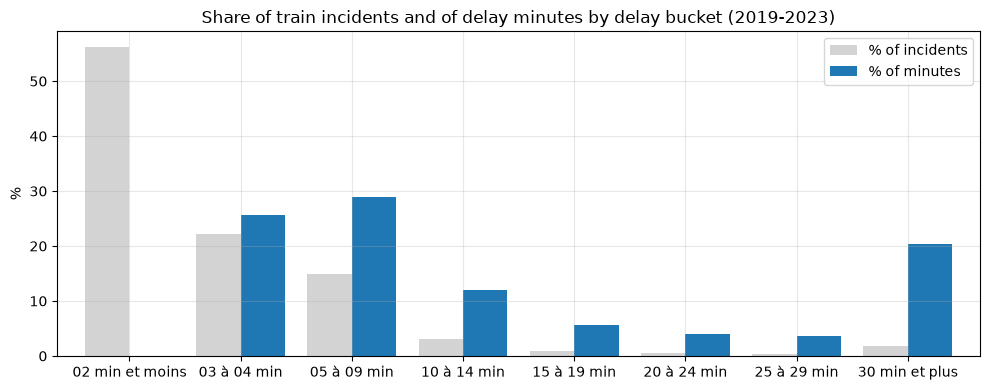

In [4]:
# Plot: share of incidents vs share of delay minutes, by delay bucket.
ax = by_bucket[["% of incidents", "% of minutes"]].plot.bar(
    color=["lightgray", "tab:blue"], width=0.8, figsize=(10, 4))
ax.set_title("Share of train incidents and of delay minutes by delay bucket (2019-2023)")
ax.set_xlabel("")
ax.set_ylabel("%")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Finding.** The shortest bucket (2 min and less) is 56% of incidents but counts
**zero** minutes, because its lower bound is 0. Most of the minutes come from the
3-4 and 5-9 min buckets (about 55%), which are common and short. The 30+ bucket is
under 2% of incidents but about 20% of minutes, *at its lower bound of 30*.

### 2b. How much the answer depends on one assumption

Recorded durations of 30+ min incidents have a median of about 52 min, so 30 is a
large understatement for them. Below: the share of delay minutes that comes from
major incidents and from each severity tier, counting 30+ incidents at 30 min (lower
bound) or at their recorded duration (floored at 30).

In [5]:
at_recorded = minutes.copy()
thirty_plus = labelled["delay_floor_minutes"] == 30
at_recorded[thirty_plus] = labelled.loc[thirty_plus, "recorded_minutes"].clip(lower=30)


def share_of_minutes(per_incident: pd.Series) -> pd.Series:
    # Share of 2019-2023 delay minutes by severity tier, in %.
    kept = per_incident[before_holdout]
    return 100 * kept.groupby(pre["severity_tier"], observed=True).sum() / kept.sum()


shares = pd.DataFrame({
    "30+ at 30 min (lower bound)": share_of_minutes(minutes),
    "30+ at recorded duration": share_of_minutes(at_recorded),
})
shares.loc["major incidents (top two tiers)"] = shares.loc[["very_long_30plus", "safety_response"]].sum()
shares.round(1)

,30+ at 30 min (lower bound),30+ at recorded duration
severity_tier,,
minor_under_5,25.1,20.2
moderate_5_to_9,26.7,21.6
long_10_to_29,16.3,13.1
very_long_30plus,3.9,6.8
safety_response,28.0,38.3
major incidents (top two tiers),31.9,45.1


**Finding.** The share of delay minutes that comes from major incidents moves from
about **32% to 45%** depending only on how long we assume 30+ incidents last. A
metric whose headline moves by 13 points on an assumption the data cannot settle is
a weak basis for choosing a model.

### 2c. Do delay minutes see the safety events?

In [6]:
safety_minutes = minutes[before_holdout & labelled["y_safety"]]
pd.Series({
    "safety responses (2019-2023)": len(safety_minutes),
    "% counting 0 delay minutes": 100 * (safety_minutes == 0).mean(),
    "% counting under 5 delay minutes": 100 * (safety_minutes < 5).mean(),
    "median delay minutes": safety_minutes.median(),
}).round(1).to_frame("value")

,value
safety responses (2019-2023),1121.0
% counting 0 delay minutes,13.7
% counting under 5 delay minutes,23.1
median delay minutes,10.0


**Finding.** About one safety response in seven counts **zero** delay minutes, and
almost one in four counts fewer than 5. A metric built on minutes alone would rank
those events below an ordinary 5-min delay. This is why the project keeps safety and
delay minutes as two separate dimensions (`documentation.md`, Decision 2).

## 3. Can a model aimed at minutes catch more of them?

Four rankings are compared in every backtest fold, all trained on the years before the
test year:

| Ranking | Trained on |
|---|---|
| major model | the main model: gradient boosting on `y_major`, safety weight 2 |
| 5+ model | gradient boosting on `y_5plus`, no safety weight |
| symptom mean minutes | average minutes of the incident's symptom (a simple benchmark) |
| minutes model | gradient boosting that predicts the minutes themselves (Poisson loss, suited to non-negative counts) |

The minutes model uses the settings the main model's tuning chose most often (learning
rate 0.03, 7 leaves, at least 100 incidents per leaf); it is not tuned further.

Measures on the test year: share of delay minutes in the top 5% and 10% of incidents,
share of major incidents and safety responses in the same top 10% (what aiming at
minutes costs), the rank correlation between predicted and actual minutes, and, for
the two minutes rankings, the share of Poisson deviance explained (D², 0 = no better
than the training average).

In [7]:
# The two classifiers, from the project's backtest (tuned on training years only).
major_predictions = run_backtest(labelled, model_names=["gradient_boosting"])["predictions"]
five_plus_predictions = run_backtest(
    labelled, target="y_5plus", safety_weight=1.0, model_names=["gradient_boosting"])["predictions"]

In [8]:
X = build_features(labelled)[MAIN_FEATURES]


def risk_of(predictions: pd.DataFrame, fold: int, incident_ids: pd.Series) -> np.ndarray:
    # Backtest risk scores of one fold, in the order of `incident_ids`.
    in_fold = predictions[predictions["fold"] == fold].set_index("incident_id")["risk"]
    return in_fold.reindex(incident_ids).to_numpy()


rows = []
for test_year, (first_year, last_year) in FOLDS.items():
    train, test = year.between(first_year, last_year), year == test_year

    minutes_model = HistGradientBoostingRegressor(
        loss="poisson", categorical_features="from_dtype", learning_rate=0.03,
        max_leaf_nodes=7, min_samples_leaf=100, max_iter=300, random_state=config.RANDOM_SEED)
    minutes_model.fit(X[train], minutes[train])

    symptom_mean = minutes[train].groupby(X.loc[train, "symptom"], observed=False).mean()
    incident_ids = labelled.loc[test, "incident_id"]
    rankings = {
        "major model": risk_of(major_predictions, test_year, incident_ids),
        "5+ model": risk_of(five_plus_predictions, test_year, incident_ids),
        "symptom mean minutes": X.loc[test, "symptom"].map(symptom_mean).astype(float)
                                 .fillna(minutes[train].mean()).to_numpy(),
        "minutes model": minutes_model.predict(X[test]),
    }

    actual = minutes[test]
    for name, score in rankings.items():
        score = pd.Series(score, index=actual.index)
        rows.append({
            "fold": test_year, "ranking": name,
            "minutes caught (top 5%)": capture(score, actual, 0.05),
            "minutes caught (top 10%)": capture(score, actual, 0.10),
            "major caught (top 10%)": capture(score, labelled.loc[test, "y_major"], 0.10),
            "safety caught (top 10%)": capture(score, labelled.loc[test, "y_safety"], 0.10),
            "rank correlation": spearmanr(score, actual).statistic,
            "deviance explained (D²)": d2_tweedie_score(actual, score, power=1)
                                       if "minutes" in name else np.nan,
        })

by_fold = pd.DataFrame(rows)
by_fold.round(3)

,fold,ranking,minutes caught (top 5%),minutes caught (top 10%),major caught (top 10%),safety caught (top 10%),rank correlation,deviance explained (D²)
0,2021,major model,0.091,0.155,0.347,0.353,0.054,NaN
1,2021,5+ model,0.105,0.186,0.146,0.149,0.269,NaN
2,2021,symptom mean minutes,0.067,0.134,0.094,0.083,0.117,0.029
3,2021,minutes model,0.124,0.191,0.144,0.144,0.249,0.089
4,2022,major model,0.093,0.143,0.388,0.408,0.085,NaN
5,2022,5+ model,0.108,0.192,0.173,0.168,0.295,NaN
6,2022,symptom mean minutes,0.064,0.125,0.091,0.077,0.139,0.037
7,2022,minutes model,0.116,0.193,0.186,0.181,0.267,0.077
8,2023,major model,0.107,0.144,0.441,0.470,0.085,NaN
9,2023,5+ model,0.090,0.180,0.124,0.117,0.313,NaN


In [9]:
# Average over the three folds.
averages = by_fold.drop(columns="fold").groupby("ranking", sort=False).mean()
averages.round(3)

,minutes caught (top 5%),minutes caught (top 10%),major caught (top 10%),safety caught (top 10%),rank correlation,deviance explained (D²)
ranking,,,,,,
major model,0.097,0.147,0.392,0.411,0.075,NaN
5+ model,0.101,0.186,0.148,0.145,0.293,NaN
symptom mean minutes,0.069,0.133,0.120,0.112,0.134,0.036
minutes model,0.116,0.190,0.164,0.158,0.266,0.089


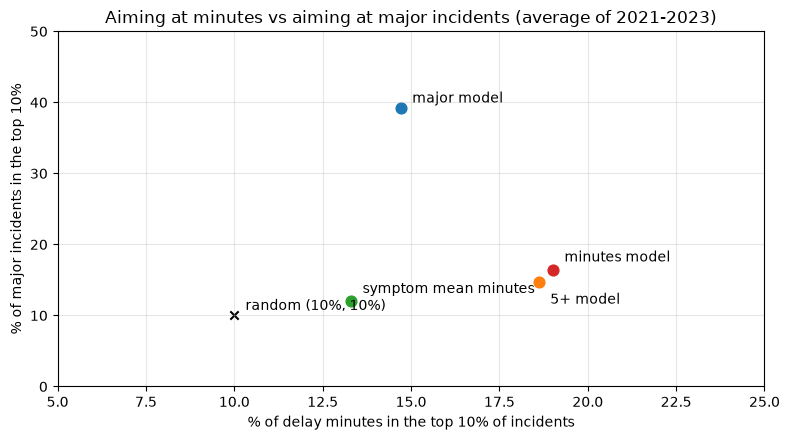

In [10]:
# Plot: what each ranking catches in its top 10%: delay minutes vs major incidents.
# Label offsets in points; the 5+ and minutes models sit close together.
label_offsets = {"5+ model": (8, -16), "minutes model": (8, 6), "symptom mean minutes": (8, 6)}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, row in averages.iterrows():
    ax.scatter(100 * row["minutes caught (top 10%)"], 100 * row["major caught (top 10%)"], s=60)
    ax.annotate(name, (100 * row["minutes caught (top 10%)"], 100 * row["major caught (top 10%)"]),
                textcoords="offset points", xytext=label_offsets.get(name, (8, 4)))
ax.scatter(10, 10, marker="x", color="black")
ax.annotate("random (10%, 10%)", (10, 10), textcoords="offset points", xytext=(8, 4))
ax.set_xlim(5, 25)
ax.set_ylim(0, 50)
ax.set_xlabel("% of delay minutes in the top 10% of incidents")
ax.set_ylabel("% of major incidents in the top 10%")
ax.set_title("Aiming at minutes vs aiming at major incidents (average of 2021-2023)")
plt.tight_layout()
plt.show()

**Findings.**
* **A model aimed at minutes does only a little better on minutes.** In its top 10% it
  catches 19.0% of delay minutes, against 18.6% for the 5+ model and 14.7% for the
  major model. Random selection would catch 10%.
* **Minutes are hard to predict from what is known at report time.** The minutes
  model explains only about 9% of the deviance, and its rank correlation with the
  actual minutes is about 0.27. The symptom alone explains under 4%.
* **Aiming at minutes gives up the major incidents.** The minutes model and the 5+
  model put only about 15% of major incidents and safety responses in their top 10%
  (14.5-16.4%), against about 40% for the major model (39.2% and 41.1%).
* So the gain on minutes (about 4 points) costs more than half of the major incidents
  caught (about 23 points).

## 4. Answer

1. **Delay minutes is a weak headline metric for this data.** It counts the most
   common bucket as zero, its main result moves from 32% to 45% on one assumption
   about 30+ incidents, and it gives many safety responses no weight at all.
2. **A model aimed at minutes does not catch many more of them.** At report time the
   data says little about how many minutes an incident will cost, so no ranking gets
   far beyond a fifth of the minutes in its top 10%.
3. **Recommendation.** Keep **safety responses and major incidents** as the target and
   headline: they are predictable (about 4x better than chance) and they are what the
   safety priority asks for. Report delay minutes as a **secondary** measure, always as
   a lower bound and with the 30+ assumption stated.

**Next.** A classification aimed at the delays themselves (for example the 5+ or 10+
threshold) can be added later as a separate view for operations, with the trade-off
above stated next to it.